# 04 — Previsão do valor da fatura

Estimativa do valor da fatura de setembro a partir das informações registradas até agosto. Comparamos modelos de regressão com duas referências simples: média histórica e valor da fatura anterior.

**Base:** UCI Default of Credit Card Clients (id 350).

## 1. Configuração

Mantemos a mesma fonte e o mesmo split dos notebooks anteriores. O alvo agora é `BILL_AMT1` (fatura de setembro), não a inadimplência.

In [1]:
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from ucimlrepo import fetch_ucirepo

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
for pasta in ["models", "reports/figures", "data/processed"]:
    (ROOT / pasta).mkdir(parents=True, exist_ok=True)

## 2. Carregamento e divisão

Reproduzimos a divisão dos notebooks 02 e 03 para manter os conjuntos comparáveis. O agrupamento de perfis iguais é usado apenas para separar registros, não como atributo dos modelos.

In [2]:
colunas = {
    "X1": "LIMIT_BAL", "X2": "SEX", "X3": "EDUCATION", "X4": "MARRIAGE",
    "X5": "AGE", "X6": "PAY_0", "X7": "PAY_2", "X8": "PAY_3",
    "X9": "PAY_4", "X10": "PAY_5", "X11": "PAY_6",
    "X12": "BILL_AMT1", "X13": "BILL_AMT2", "X14": "BILL_AMT3",
    "X15": "BILL_AMT4", "X16": "BILL_AMT5", "X17": "BILL_AMT6",
    "X18": "PAY_AMT1", "X19": "PAY_AMT2", "X20": "PAY_AMT3",
    "X21": "PAY_AMT4", "X22": "PAY_AMT5", "X23": "PAY_AMT6"
}

dataset = fetch_ucirepo(id=350)
base = dataset.data.features.rename(columns=colunas).drop(columns="ID", errors="ignore").copy()
alvo_inadimplencia = dataset.data.targets.iloc[:, 0].astype(int)

assert set(colunas.values()).issubset(base.columns)
assert len(base) == len(alvo_inadimplencia)

grupos = pd.util.hash_pandas_object(base, index=False)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_treino, idx_teste = next(splitter.split(base, alvo_inadimplencia, groups=grupos))

treino = base.iloc[idx_treino].copy()
teste = base.iloc[idx_teste].copy()
grupo_treino = grupos.iloc[idx_treino]

assert set(grupos.iloc[idx_treino]).isdisjoint(set(grupos.iloc[idx_teste]))
print("Treino:", treino.shape, "| Teste:", teste.shape)

Treino: (24000, 23) | Teste: (6000, 23)


## 3. Variáveis disponíveis até agosto

Para estimar a fatura de setembro, usamos limite de crédito, faturas, pagamentos e status de pagamento **até agosto**. Excluímos `PAY_0`, `PAY_AMT1` e `BILL_AMT1` da matriz de entrada. Também não usamos o rótulo de inadimplência, que só seria conhecido depois.

In [3]:
colunas_modelo = (
    ["LIMIT_BAL"]
    + [f"PAY_{i}" for i in range(2, 7)]
    + [f"BILL_AMT{i}" for i in range(2, 7)]
    + [f"PAY_AMT{i}" for i in range(2, 7)]
)

X_train = treino[colunas_modelo].copy()
X_test = teste[colunas_modelo].copy()
y_train = treino["BILL_AMT1"].copy()
y_test = teste["BILL_AMT1"].copy()

assert not {"BILL_AMT1", "PAY_AMT1", "PAY_0"}.intersection(X_train.columns)
assert not X_train.isna().any().any() and not X_test.isna().any().any()
print("Atributos:", len(colunas_modelo))
display(y_train.describe(percentiles=[0.01, 0.5, 0.95, 0.99]).to_frame("BILL_AMT1"))

Atributos: 16


,BILL_AMT1
count,24000.000000
mean,51473.288667
std,73917.201667
min,-165580.000000
1%,-84.050000
50%,22619.000000
95%,201421.150000
99%,350756.800000
max,964511.000000


## 4. Referências e métricas

Usamos MAE e RMSE para medir o erro em valores monetários da base. O RMSE penaliza mais erros grandes. A fatura de agosto funciona como uma referência prática: muitos clientes podem manter valores parecidos de um mês para o outro.

In [4]:
def calcular_metricas(real, previsto):
    return {
        "MAE": mean_absolute_error(real, previsto),
        "RMSE": np.sqrt(mean_squared_error(real, previsto)),
        "R2": r2_score(real, previsto)
    }

# Referências calculadas sem consultar o teste
media_treino = float(y_train.mean())
referencias_treino = {
    "Média do treino": np.full(len(y_train), media_treino),
    "Fatura anterior": X_train["BILL_AMT2"].to_numpy()
}

referencias = pd.DataFrame([
    {"modelo": nome, **calcular_metricas(y_train, prev)}
    for nome, prev in referencias_treino.items()
]).set_index("modelo")
print("Baselines no treino (apenas referência):")
display(referencias.round(2))

Baselines no treino (apenas referência):


,MAE,RMSE,R2
modelo,,,
Média do treino,50692.72,73915.66,0.00
Fatura anterior,7635.48,22441.77,0.91


## 5. Treinamento e validação cruzada

Comparamos Ridge e Gradient Boosting, usando MAE como critério de seleção. A validação cruzada respeita os grupos de registros idênticos. O pré-processamento da Ridge é ajustado dentro de cada fold.

In [5]:
financeiras = ["LIMIT_BAL"] + [f"BILL_AMT{i}" for i in range(2, 7)] + [f"PAY_AMT{i}" for i in range(2, 7)]
status = [f"PAY_{i}" for i in range(2, 7)]

preprocessamento = ColumnTransformer([
    ("financeiras", Pipeline([
        ("arcsinh", FunctionTransformer(np.arcsinh, validate=False)),
        ("escala", StandardScaler())
    ]), financeiras),
    ("status", StandardScaler(), status)
])

modelos = {
    "Ridge": Pipeline([
        ("preprocessamento", preprocessamento),
        ("modelo", Ridge(alpha=10.0))
    ]),
    "Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=160, max_leaf_nodes=25, learning_rate=0.06,
        l2_regularization=10.0, random_state=RANDOM_STATE
    )
}

cv = GroupKFold(n_splits=3)
linhas = []
for nome, modelo in modelos.items():
    print("Validando:", nome)
    scores = cross_validate(
        modelo, X_train, y_train, groups=grupo_treino,
        cv=cv, scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        }, n_jobs=1
    )
    linhas.append({
        "modelo": nome,
        "MAE_CV": -scores["test_mae"].mean(),
        "RMSE_CV": -scores["test_rmse"].mean(),
        "R2_CV": scores["test_r2"].mean(),
        "desvio_MAE": scores["test_mae"].std()
    })

comparacao_cv = pd.DataFrame(linhas).set_index("modelo").sort_values("MAE_CV")
display(comparacao_cv.round(2))
modelo_escolhido = comparacao_cv.index[0]
print("Modelo escolhido:", modelo_escolhido)

Validando: Ridge
Validando: Gradient Boosting


,MAE_CV,RMSE_CV,R2_CV,desvio_MAE
modelo,,,,
Gradient Boosting,8382.15,21164.58,0.92,63.75
Ridge,39598.68,59004.44,0.36,592.99


Modelo escolhido: Gradient Boosting


## 6. Avaliação no teste

O teste não é usado na escolha do modelo. Comparamos o resultado final com a média calculada no treino e com a última fatura conhecida.

In [6]:
modelo_final = modelos[modelo_escolhido]
modelo_final.fit(X_train, y_train)
pred_teste = modelo_final.predict(X_test)

previsoes_teste = {
    "Média do treino": np.full(len(y_test), media_treino),
    "Fatura anterior": X_test["BILL_AMT2"].to_numpy(),
    modelo_escolhido: pred_teste
}

metricas_teste = pd.DataFrame([
    {"modelo": nome, **calcular_metricas(y_test, prev)}
    for nome, prev in previsoes_teste.items()
]).set_index("modelo").sort_values("MAE")
display(metricas_teste.round(2))

melhor_baseline = metricas_teste.loc[["Média do treino", "Fatura anterior"], "MAE"].min()
mae_modelo = metricas_teste.loc[modelo_escolhido, "MAE"]
print("Diferença de MAE para o melhor baseline:", round(mae_modelo - melhor_baseline, 2))
print("Valor negativo indica melhora sobre o baseline.")

,MAE,RMSE,R2
modelo,,,
Fatura anterior,7685.73,24068.63,0.89
Gradient Boosting,8003.10,21833.45,0.91
Média do treino,50229.03,72501.78,-0.00


Diferença de MAE para o melhor baseline: 317.36
Valor negativo indica melhora sobre o baseline.


## 7. Erros de previsão

A distribuição dos resíduos ajuda a identificar erros extremos. A linha tracejada no gráfico de dispersão indica previsão perfeita.

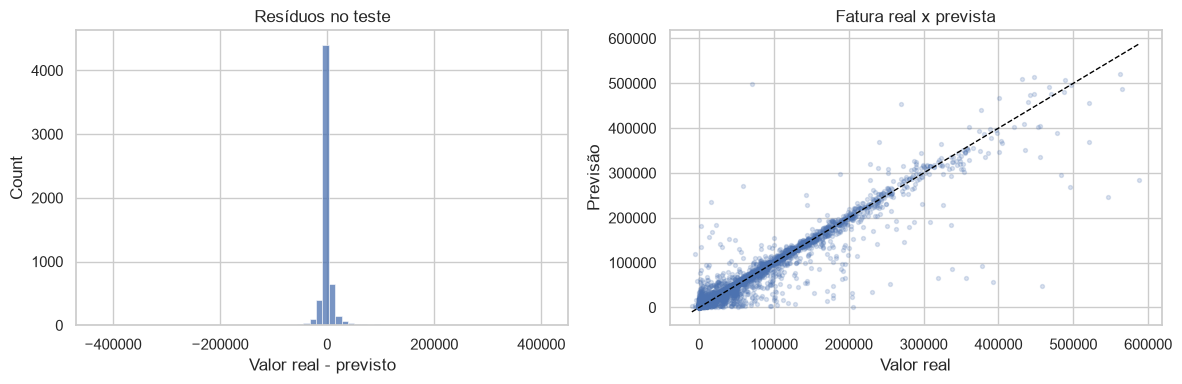

Erro absoluto mediano: 2977.4
Percentual de faturas negativas no teste: 1.80%


In [7]:
residuos = y_test.to_numpy() - pred_teste
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(residuos, bins=70, ax=axes[0])
axes[0].set(title="Resíduos no teste", xlabel="Valor real - previsto")

axes[1].scatter(y_test, pred_teste, s=8, alpha=0.20)
limites = [min(y_test.min(), pred_teste.min()), max(y_test.max(), pred_teste.max())]
axes[1].plot(limites, limites, linestyle="--", color="black", linewidth=1)
axes[1].set(title="Fatura real x prevista", xlabel="Valor real", ylabel="Previsão")
plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "04_erros_regressao.png", dpi=140)
plt.show()

print("Erro absoluto mediano:", round(float(np.median(np.abs(residuos))), 2))
print("Percentual de faturas negativas no teste:", f"{(y_test < 0).mean():.2%}")

## 8. Exportação

Salvamos o modelo, as previsões e as métricas para uso posterior no dashboard. `row_id` é o índice da base carregada, não identifica uma pessoa.

In [8]:
joblib.dump(modelo_final, ROOT / "models" / "regressao_fatura.joblib")

saida = pd.DataFrame({
    "row_id": X_test.index,
    "fatura_real": y_test.to_numpy(),
    "fatura_prevista": pred_teste,
    "fatura_anterior": X_test["BILL_AMT2"].to_numpy()
})
saida["erro_absoluto"] = (saida["fatura_real"] - saida["fatura_prevista"]).abs()
saida.to_csv(ROOT / "data" / "processed" / "previsoes_fatura_teste.csv", index=False)
metricas_teste.to_csv(ROOT / "data" / "processed" / "metricas_regressao.csv")

metadados = {
    "dataset": "UCI Default of Credit Card Clients (id=350)",
    "alvo": "BILL_AMT1",
    "periodo_das_features": "até agosto de 2005",
    "features": colunas_modelo,
    "modelo": modelo_escolhido,
    "selecao": "menor MAE em GroupKFold (3 folds) no treino",
    "random_state": RANDOM_STATE
}
(ROOT / "models" / "regressao_metadata.json").write_text(
    json.dumps(metadados, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Arquivos salvos em models/, data/processed/ e reports/figures/.")

Arquivos salvos em models/, data/processed/ e reports/figures/.


## 9. Conclusão

O **Gradient Boosting** apresentou o menor MAE entre os modelos avaliados na validação cruzada (8.382,15), à frente da Ridge (39.598,68).

No teste, o Gradient Boosting obteve **MAE de 8.003,10**, **RMSE de 21.833,45** e **R² de 0,91**. A referência baseada na fatura de agosto teve **MAE de 7.685,73** e **RMSE de 24.068,63**.

Assim, a fatura anterior foi a melhor opção em MAE, com vantagem de 317,36. O Gradient Boosting, por outro lado, teve RMSE cerca de 9,3% menor, indicando menor impacto dos erros de maior magnitude nesse conjunto. O erro absoluto mediano do modelo foi de 2.977,40.

Os valores negativos de fatura foram mantidos como registrados na base (1,80% do teste), sem assumir que sejam erros de cadastro. A base é histórica e apresenta um período por cliente; por isso, a avaliação não substitui uma validação temporal com dados futuros. As métricas estão nas unidades monetárias originais da base, não em reais.

**Próximo notebook:** `05_estatistica.ipynb`.
